In [51]:
# Initialize Otter
import otter
grader = otter.Notebook("project1.ipynb")

# Midterm Project: Exploring USA County Health Rankings and Roadmaps

### Collaborators and Sources
In addition to recording your **collaborators** (TAs, peers, group members, roommates, etc.) on this homework in the cell below, you are required to **cite/indicate all external sources** used when finishing this assignment. 
External sources are defined as anything that is not considered course material, such as online sources (webpages, blog posts, etc.), content generated by AI systems, books, etc.

When using external sources, indicate what kind of external sources (e.g. stack overflow, WashU chatGPT, etc.) you used in the cell below and then provide more specific citations (such as links to webpages or in case of AI generated asnwers the actual sources (links provided by the AI system) and the prompt used to generate the answers) with your answer to **each specific problem**.  


Note that these citations will not free you from your obligation to submit your _own_ code and write-ups, however, they will be taken into account during the grading and regrading process, **especially** when two or more submissions closely resemble each other. Working with each other is ok, as long as you cite who you worked with and you don't copy anyone's answers directly!

### Submission instructions
* Submit this Python notebook on Gradescope.
* Execute all cells and save your notebook prior to submission. 
* Don't forget to commit and push to your Github repo!
* **Do not change the number of cells!** Your submission notebook should have exactly one code cell per problem. 
* Do **not** remove the `# your code here` line. Add your solution **after** that line. 

### Submission instructions
* Submit this Python notebook, including your answers in the code cells as homework submission.
* **Feel free to add as many cells as you need to** — just make sure you don't change what we gave you. 
* **Does it spark joy?** Note that you will be partially graded on the presentation (_cleanliness, clarity, comments_) of your notebook so make sure you [Marie Kondo](https://lifehacker.com/marie-kondo-is-not-a-verb-1833373654) your notebook before submitting it.

## 1. Introduction

We are using the 2024 County Health Release National Data compiled and curated by the County Health Rankings & Roadmaps (CHR&R), a program of the University of Wisconsin Population Health Institute. It provides data at the county-level to enable analysis of the reasons for the differences in health within each community and across communities. (https://www.countyhealthrankings.org/).

For our midterm project this semester, the data (analytic_data2024.csv) and the data dictionary is already stored in this box folder (https://wustl.box.com/s/6sobk3ae12bup7ccp29y964q1pyuu0l7) for your convinence or you can also download it from https://www.countyhealthrankings.org/health-data/methodology-and-sources/data-documentation (2024 CHR CSV Analytic Data)

Our goal will be to use the clean dataset (analytic_data2024.csv) to gain some insight about US County Health Rankings & Roadmaps (CHR&R) characteristics and (_hopefully_) find some patterns in this data.

In general, we will be following the EDA process:
1. Get the data and gain **basic understanding**
2. **Wrangle** the data
3. **Profile** the data
4. Develop questions to investigate (form a **hypotheses**)
5. Use the data to **investigate** hypothesis
6. **Summarize** results and answer questions 
7. **Critically review** our workflow and discuss ethical concerns

In [52]:
# Load dataset
import os
os.getcwd()
import pandas as pd
df = pd.read_csv('utility/data/analytic_data2024.csv', low_memory=False)
df.head()

,State FIPS Code,County FIPS Code,5-digit FIPS Code,State Abbreviation,Name,Release Year,County Clustered (Yes=1/No=0),Premature Death raw value,Premature Death numerator,Premature Death denominator,...,% Female raw value,% Female numerator,% Female denominator,% Female CI low,% Female CI high,% Rural raw value,% Rural numerator,% Rural denominator,% Rural CI low,% Rural CI high
0,statecode,countycode,fipscode,state,county,year,county_clustered,v001_rawvalue,v001_numerator,v001_denominator,...,v057_rawvalue,v057_numerator,v057_denominator,v057_cilow,v057_cihigh,v058_rawvalue,v058_numerator,v058_denominator,v058_cilow,v058_cihigh
1,00,000,00000,US,United States,2024,NaN,7971.5097891,4535347,921750763,...,0.504081237,168004004,333287557,NaN,NaN,0.2000313707,66300254,331449281,NaN,NaN
2,01,000,01000,AL,Alabama,2024,NaN,11415.734833,98140,13812804,...,0.5137532379,2606936,5074296,NaN,NaN,0.4226276049,2123399,5024279,NaN,NaN
3,01,001,01001,AL,Autauga County,2024,1,9407.9484384,942,159452,...,0.5129603909,30654,59759,NaN,NaN,0.406768132,23920,58805,NaN,NaN
4,01,003,01003,AL,Baldwin County,2024,1,8981.5753533,3789,633571,...,0.5123906913,126271,246435,NaN,NaN,0.3758645536,87113,231767,NaN,NaN


## 2. Getting Familiar with the Data

In this section, we will get a feel for our data and tidy it up so that we can analyize it later. 
Download the data from the source/link given above and be sure to save the data in a folder called `data` under the `utility` directory. Your final path should look like `utility/data/analytic_data2024.csv` -- if it doesn't **we will not be able to properly grade your assignment!**



<!-- BEGIN QUESTION -->

### Problem 1

Let's start by taking a look at our data and the README that includes essential information for the data. 

**Write-up!** Describe the data, answering questions including, but not limited to, these: Where does the data come from? How was it obtained? How many examples (rows) and features (columns) does the dataset have? What kinds of features are in the dataset -- numerical  (discrete/continuous) or categorical(ordinal/nominal)? What range of values does each feature  take? List five or more features you find the most relevant and would like to explore further. 
> **Hint**: Consider the steps of EDA; what would you like to know about this dataset. 

**Answer here:** (feel free to make multiple cells!)  

The dataset has 3196 rows and 770 features. It came from the "County Health Rankings & Roadmaps program", compiling datasets from counties across the U.S. using sources like the CDC and Census Bereau.
There are some nominal categorical variables, like the State Abbreviation or the name of the county.
There are many continuous numerical variables, like "Life Expectancy", "Drug Overdose Deaths raw value", and "Median Household Income".
There are some discrete numerical variables like "Numerators / denominators (counts)" and "Population"

In [53]:
print(df.shape)
df.columns

(3196, 770)


Index(['State FIPS Code', 'County FIPS Code', '5-digit FIPS Code',
       'State Abbreviation', 'Name', 'Release Year',
       'County Clustered (Yes=1/No=0)', 'Premature Death raw value',
       'Premature Death numerator', 'Premature Death denominator',
       ...
       '% Female raw value', '% Female numerator', '% Female denominator',
       '% Female CI low', '% Female CI high', '% Rural raw value',
       '% Rural numerator', '% Rural denominator', '% Rural CI low',
       '% Rural CI high'],
      dtype='object', length=770)

### Problem 2

Data cleaning and processing: Let's do some data wrangling. 

**Write up!** Considering your description of the dataset from [Problem 1](#Problem-1), how should we clean this data?

Here are some initial instructions to get you started and feel free to do further cleaning if it makes sense for your data analytics:
- Retain only the following columns: 'State FIPS Code', 'County FIPS Code', '5-digit FIPS Code', 'Name', 'State Abbreviation', 'Release Year' and all the '*_raw value'. Report any changes in data size or shape after each update or reduction.
> **Hint** You can use the `endswith()` function or regex to get the column names that end with a specific suffix.
- Remove the rows corresponding to the aggregate values for the entire US and one for each state and District of Columbia. **These rows have a “County FIPS Code” value of “000”.**
- Remove columns where over 10% of the values are missing values. This should bring the number of columns down to ~75.
> **Hint** Use the `df.dropna(axis=1, thresh=n)` method, where n is the minimum number of non-missing values a column must have to be retained. Given that a column should have at least 90% of its values present, how would you determine `n`?

- Keep only complete rows, i.e., remove rows with any missing value.
- Feel free to rename the columns, making them more meaningful.
- Drop the first row of the dataset.
- Covert the '*_raw value' columns to a numeric data type.
> **Hint** Use `lambda` and `pd.to_numeric`
- Based on the goals of your project, feel free to get rid of more features to keep your dataset more aligned with your project goals and further analysis.

**Do this!** In the cells below, **explain** and perform the steps that you need to prepare this data for further analysis. Make sure that your implementations and write-ups (for processing and analysis) are presented well and effectively describe your workflow. You should add comments and markdown cells for your documentation as you see fit!  


*Grading Note: Your work will be graded for _readability_, _style_, and _cleanlines_. So, carefully document your code and use descriptive/intuitive variable names. For write-ups use consice and clear language like in a written project report.*

> **Hint**: You can use our previous labs as examples of how you might do this. 
Also, you might want to come back to this step later on, since you might encounter problems with the data once you actually analyze it. Remember, you may add as many cells (for code and text) as you need below. Here — we gave you one for free!

In [54]:
# this one is free!

First, we will get rid of the columns other than 'State FIPS Code', 'County FIPS Code', '5-digit FIPS Code', 'Name', 'State Abbreviation', 'Release Year' and all the '*_raw value'.

In [55]:
raw_value = [x for x in df.columns if x.endswith('raw value')]
df1 = df.loc[:,['State FIPS Code', 'County FIPS Code', '5-digit FIPS Code', 'Name', 'State Abbreviation', 'Release Year'] + raw_value]
df1.head()

,State FIPS Code,County FIPS Code,5-digit FIPS Code,Name,State Abbreviation,Release Year,Premature Death raw value,Poor or Fair Health raw value,Poor Physical Health Days raw value,Poor Mental Health Days raw value,...,% 65 and Older raw value,% Non-Hispanic Black raw value,% American Indian or Alaska Native raw value,% Asian raw value,% Native Hawaiian or Other Pacific Islander raw value,% Hispanic raw value,% Non-Hispanic White raw value,% Not Proficient in English raw value,% Female raw value,% Rural raw value
0,statecode,countycode,fipscode,county,state,year,v001_rawvalue,v002_rawvalue,v036_rawvalue,v042_rawvalue,...,v053_rawvalue,v054_rawvalue,v055_rawvalue,v081_rawvalue,v080_rawvalue,v056_rawvalue,v126_rawvalue,v059_rawvalue,v057_rawvalue,v058_rawvalue
1,00,000,00000,United States,US,2024,7971.5097891,0.142,3.3462999489,4.8171219478,...,0.17340837,0.1262287479,0.0131485077,0.0628704569,0.0026367861,0.1910192705,0.5887587517,0.040955371,0.504081237,0.2000313707
2,01,000,01000,Alabama,AL,2024,11415.734833,0.178,3.9347354029,5.869319841,...,0.1802679623,0.26430898,0.0071586285,0.0158869329,0.0010949302,0.0493177773,0.6471171567,0.0104749848,0.5137532379,0.4226276049
3,01,001,01001,Autauga County,AL,2024,9407.9484384,0.173,3.9102650589,5.7032041246,...,0.1641091718,0.210110611,0.0047189545,0.0117806523,0.0012215733,0.0338191737,0.7205107181,0.0036648553,0.5129603909,0.406768132
4,01,003,01003,Baldwin County,AL,2024,8981.5753533,0.152,3.7309428675,5.3736661513,...,0.2192870331,0.0822488689,0.0081076146,0.0115608578,0.0006654899,0.0503621645,0.8297847303,0.0078665799,0.5123906913,0.3758645536


In [56]:
df1.shape

(3196, 91)

We dropped 679 columns, so now we are working with 91 columns.

Now we will remove rows with “County FIPS Code” value of “000”

In [57]:
df2 = df1[df1['County FIPS Code'] != '000']
df2.head()

,State FIPS Code,County FIPS Code,5-digit FIPS Code,Name,State Abbreviation,Release Year,Premature Death raw value,Poor or Fair Health raw value,Poor Physical Health Days raw value,Poor Mental Health Days raw value,...,% 65 and Older raw value,% Non-Hispanic Black raw value,% American Indian or Alaska Native raw value,% Asian raw value,% Native Hawaiian or Other Pacific Islander raw value,% Hispanic raw value,% Non-Hispanic White raw value,% Not Proficient in English raw value,% Female raw value,% Rural raw value
0,statecode,countycode,fipscode,county,state,year,v001_rawvalue,v002_rawvalue,v036_rawvalue,v042_rawvalue,...,v053_rawvalue,v054_rawvalue,v055_rawvalue,v081_rawvalue,v080_rawvalue,v056_rawvalue,v126_rawvalue,v059_rawvalue,v057_rawvalue,v058_rawvalue
3,01,001,01001,Autauga County,AL,2024,9407.9484384,0.173,3.9102650589,5.7032041246,...,0.1641091718,0.210110611,0.0047189545,0.0117806523,0.0012215733,0.0338191737,0.7205107181,0.0036648553,0.5129603909,0.406768132
4,01,003,01003,Baldwin County,AL,2024,8981.5753533,0.152,3.7309428675,5.3736661513,...,0.2192870331,0.0822488689,0.0081076146,0.0115608578,0.0006654899,0.0503621645,0.8297847303,0.0078665799,0.5123906913,0.3758645536
5,01,005,01005,Barbour County,AL,2024,13138.848362,0.273,5.0234883184,6.0142940199,...,0.2062252085,0.4719501336,0.0072452036,0.0046952157,0.0027928438,0.0509997571,0.4527240346,0.0198065994,0.4712215656,0.6591999366
6,01,007,01007,Bibb County,AL,2024,12675.434581,0.22,4.552794934,5.8245833931,...,0.1780504431,0.2073619632,0.0057259714,0.0029084299,0.0013178823,0.0317655078,0.739968189,0.0028918176,0.4648943422,1


In [58]:
df2.shape

(3144, 91)

We dropped 52 rows, so we now have 3144 rows.

Now we will remove columns where over 10% of the values are missing values.

In [59]:
threshold = 0.9 * len(df2)
df3 = df2.dropna(axis=1, thresh = threshold)
print(df3.shape)
df3.head()

(3144, 75)


,State FIPS Code,County FIPS Code,5-digit FIPS Code,Name,State Abbreviation,Release Year,Premature Death raw value,Poor or Fair Health raw value,Poor Physical Health Days raw value,Poor Mental Health Days raw value,...,% 65 and Older raw value,% Non-Hispanic Black raw value,% American Indian or Alaska Native raw value,% Asian raw value,% Native Hawaiian or Other Pacific Islander raw value,% Hispanic raw value,% Non-Hispanic White raw value,% Not Proficient in English raw value,% Female raw value,% Rural raw value
0,statecode,countycode,fipscode,county,state,year,v001_rawvalue,v002_rawvalue,v036_rawvalue,v042_rawvalue,...,v053_rawvalue,v054_rawvalue,v055_rawvalue,v081_rawvalue,v080_rawvalue,v056_rawvalue,v126_rawvalue,v059_rawvalue,v057_rawvalue,v058_rawvalue
3,01,001,01001,Autauga County,AL,2024,9407.9484384,0.173,3.9102650589,5.7032041246,...,0.1641091718,0.210110611,0.0047189545,0.0117806523,0.0012215733,0.0338191737,0.7205107181,0.0036648553,0.5129603909,0.406768132
4,01,003,01003,Baldwin County,AL,2024,8981.5753533,0.152,3.7309428675,5.3736661513,...,0.2192870331,0.0822488689,0.0081076146,0.0115608578,0.0006654899,0.0503621645,0.8297847303,0.0078665799,0.5123906913,0.3758645536
5,01,005,01005,Barbour County,AL,2024,13138.848362,0.273,5.0234883184,6.0142940199,...,0.2062252085,0.4719501336,0.0072452036,0.0046952157,0.0027928438,0.0509997571,0.4527240346,0.0198065994,0.4712215656,0.6591999366
6,01,007,01007,Bibb County,AL,2024,12675.434581,0.22,4.552794934,5.8245833931,...,0.1780504431,0.2073619632,0.0057259714,0.0029084299,0.0013178823,0.0317655078,0.739968189,0.0028918176,0.4648943422,1


We dropped 16 columns, so we now have 75 columns.

Now we will remove any rows that are missing any values.

In [60]:
df4 = df3.dropna(axis=0)
print(df4.shape)
df4.head()

(2450, 75)


,State FIPS Code,County FIPS Code,5-digit FIPS Code,Name,State Abbreviation,Release Year,Premature Death raw value,Poor or Fair Health raw value,Poor Physical Health Days raw value,Poor Mental Health Days raw value,...,% 65 and Older raw value,% Non-Hispanic Black raw value,% American Indian or Alaska Native raw value,% Asian raw value,% Native Hawaiian or Other Pacific Islander raw value,% Hispanic raw value,% Non-Hispanic White raw value,% Not Proficient in English raw value,% Female raw value,% Rural raw value
0,statecode,countycode,fipscode,county,state,year,v001_rawvalue,v002_rawvalue,v036_rawvalue,v042_rawvalue,...,v053_rawvalue,v054_rawvalue,v055_rawvalue,v081_rawvalue,v080_rawvalue,v056_rawvalue,v126_rawvalue,v059_rawvalue,v057_rawvalue,v058_rawvalue
3,01,001,01001,Autauga County,AL,2024,9407.9484384,0.173,3.9102650589,5.7032041246,...,0.1641091718,0.210110611,0.0047189545,0.0117806523,0.0012215733,0.0338191737,0.7205107181,0.0036648553,0.5129603909,0.406768132
4,01,003,01003,Baldwin County,AL,2024,8981.5753533,0.152,3.7309428675,5.3736661513,...,0.2192870331,0.0822488689,0.0081076146,0.0115608578,0.0006654899,0.0503621645,0.8297847303,0.0078665799,0.5123906913,0.3758645536
5,01,005,01005,Barbour County,AL,2024,13138.848362,0.273,5.0234883184,6.0142940199,...,0.2062252085,0.4719501336,0.0072452036,0.0046952157,0.0027928438,0.0509997571,0.4527240346,0.0198065994,0.4712215656,0.6591999366
6,01,007,01007,Bibb County,AL,2024,12675.434581,0.22,4.552794934,5.8245833931,...,0.1780504431,0.2073619632,0.0057259714,0.0029084299,0.0013178823,0.0317655078,0.739968189,0.0028918176,0.4648943422,1


We dropped 694 rows, so now we have 2450 rows.

We will also drop the first row, as it does not provide any data; it is a descriptor of the column.

In [61]:
df5 = df4.drop(labels=[0])
df5.head()

,State FIPS Code,County FIPS Code,5-digit FIPS Code,Name,State Abbreviation,Release Year,Premature Death raw value,Poor or Fair Health raw value,Poor Physical Health Days raw value,Poor Mental Health Days raw value,...,% 65 and Older raw value,% Non-Hispanic Black raw value,% American Indian or Alaska Native raw value,% Asian raw value,% Native Hawaiian or Other Pacific Islander raw value,% Hispanic raw value,% Non-Hispanic White raw value,% Not Proficient in English raw value,% Female raw value,% Rural raw value
3,01,001,01001,Autauga County,AL,2024,9407.9484384,0.173,3.9102650589,5.7032041246,...,0.1641091718,0.210110611,0.0047189545,0.0117806523,0.0012215733,0.0338191737,0.7205107181,0.0036648553,0.5129603909,0.406768132
4,01,003,01003,Baldwin County,AL,2024,8981.5753533,0.152,3.7309428675,5.3736661513,...,0.2192870331,0.0822488689,0.0081076146,0.0115608578,0.0006654899,0.0503621645,0.8297847303,0.0078665799,0.5123906913,0.3758645536
5,01,005,01005,Barbour County,AL,2024,13138.848362,0.273,5.0234883184,6.0142940199,...,0.2062252085,0.4719501336,0.0072452036,0.0046952157,0.0027928438,0.0509997571,0.4527240346,0.0198065994,0.4712215656,0.6591999366
6,01,007,01007,Bibb County,AL,2024,12675.434581,0.22,4.552794934,5.8245833931,...,0.1780504431,0.2073619632,0.0057259714,0.0029084299,0.0013178823,0.0317655078,0.739968189,0.0028918176,0.4648943422,1
7,01,009,01009,Blount County,AL,2024,11541.495069,0.186,4.2463351824,5.6648506119,...,0.1909026751,0.0172738271,0.0063348568,0.0043520634,0.00131066,0.1007023794,0.8599274096,0.0219519644,0.5029069767,0.9048939696


Data in columns ending in 'raw value' are stored as strings, so we need to convert them to numeric data types.

In [62]:
df_final = df5.apply(lambda col: pd.to_numeric(col) if col.name.endswith('raw value') else col)
df_final.head()

,State FIPS Code,County FIPS Code,5-digit FIPS Code,Name,State Abbreviation,Release Year,Premature Death raw value,Poor or Fair Health raw value,Poor Physical Health Days raw value,Poor Mental Health Days raw value,...,% 65 and Older raw value,% Non-Hispanic Black raw value,% American Indian or Alaska Native raw value,% Asian raw value,% Native Hawaiian or Other Pacific Islander raw value,% Hispanic raw value,% Non-Hispanic White raw value,% Not Proficient in English raw value,% Female raw value,% Rural raw value
3,01,001,01001,Autauga County,AL,2024,9407.948438,0.173,3.910265,5.703204,...,0.164109,0.210111,0.004719,0.011781,0.001222,0.033819,0.720511,0.003665,0.512960,0.406768
4,01,003,01003,Baldwin County,AL,2024,8981.575353,0.152,3.730943,5.373666,...,0.219287,0.082249,0.008108,0.011561,0.000665,0.050362,0.829785,0.007867,0.512391,0.375865
5,01,005,01005,Barbour County,AL,2024,13138.848362,0.273,5.023488,6.014294,...,0.206225,0.471950,0.007245,0.004695,0.002793,0.051000,0.452724,0.019807,0.471222,0.659200
6,01,007,01007,Bibb County,AL,2024,12675.434581,0.220,4.552795,5.824583,...,0.178050,0.207362,0.005726,0.002908,0.001318,0.031766,0.739968,0.002892,0.464894,1.000000
7,01,009,01009,Blount County,AL,2024,11541.495069,0.186,4.246335,5.664851,...,0.190903,0.017274,0.006335,0.004352,0.001311,0.100702,0.859927,0.021952,0.502907,0.904894


### Problem 3

Formulating and Answering Questions Through Analysis and Visualizations 

**Do this!** Now that we cleaned up our data, we are ready to look into it. In this problem, we want to profile our data and explore its variables.

> **Hint**: Note that the way some data is stored does not necesarily mean that each column should correspond to a seperate variable. Feel free to define your own variables based on the input data. Looking at the dataset documentation (data dictionary) might be helpful to figure out meaningful representations. Also note that there are no right or wrong representations here (since it is your job to find something interesting in the data, it is also up to you to choose the data/variable representations). Again, you might want to iterate over this step again later after doing some more exploration. 

> **Hint**: Recall from Lab 2, this step usually involves computing summary statistics and basic plots _where applicable_. Try plotting some of the data (with appropriate plots; remember the lecture content - some plots introduced in there ( we did not yet use in the lab or hw) could be useful). Then, highlight a few of the more interesting ones and discuss why you thought they were interesting — for both our sakes, **please only include the most interesting ones** in your actual submission!!  Again note that there are no right or wrong features to choose here (since it is your job to find something interesting in the data, it is also up to you to choose the data/variables to include). Just be sure to make a selection. You will not receive any credit by simply plotting everything!  

*Grading Note*: Your work will be graded for _creativity_ and _aesthetics_. Be creative in the plots you use and select visulatizations and colors that make for a plesant and intuitive viewing expereince. The goal of a good visualization is that the viewer will quickly understand your figures.* 

Once again, we have provided a _free_ cell for you to use; make as many as you need. Use text/markdown cells to describe what you are doing and what your findings are. 

In [63]:
df_final.columns

Index(['State FIPS Code', 'County FIPS Code', '5-digit FIPS Code', 'Name',
       'State Abbreviation', 'Release Year', 'Premature Death raw value',
       'Poor or Fair Health raw value', 'Poor Physical Health Days raw value',
       'Poor Mental Health Days raw value', 'Low Birthweight raw value',
       'Adult Smoking raw value', 'Adult Obesity raw value',
       'Food Environment Index raw value', 'Physical Inactivity raw value',
       'Access to Exercise Opportunities raw value',
       'Excessive Drinking raw value',
       'Alcohol-Impaired Driving Deaths raw value',
       'Sexually Transmitted Infections raw value', 'Teen Births raw value',
       'Uninsured raw value', 'Primary Care Physicians raw value',
       'Dentists raw value', 'Mental Health Providers raw value',
       'Preventable Hospital Stays raw value',
       'Mammography Screening raw value', 'Flu Vaccinations raw value',
       'High School Completion raw value', 'Some College raw value',
       'Unemployment

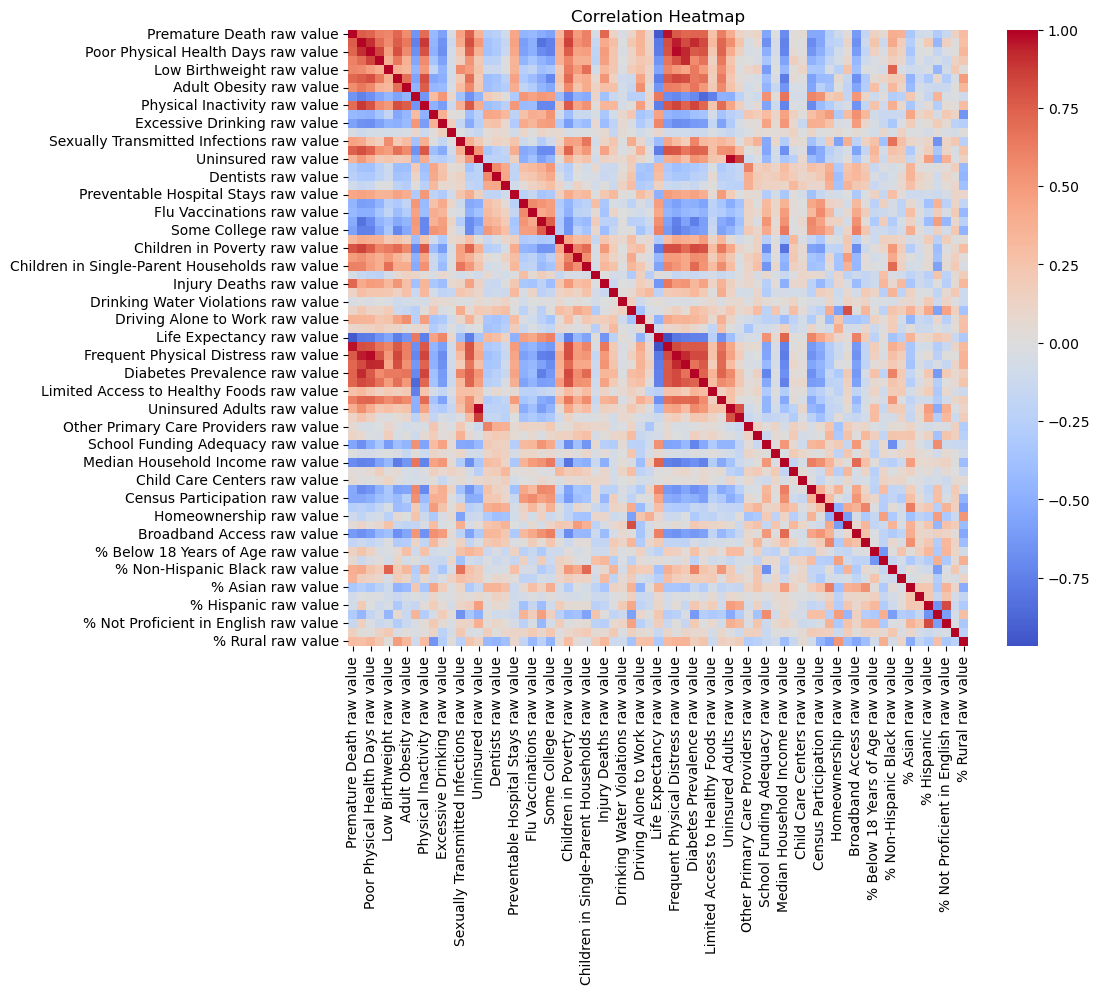

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df_final.corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

In [65]:
# this one is also free!

First, we will think about features that could be correlated with **teen births**.

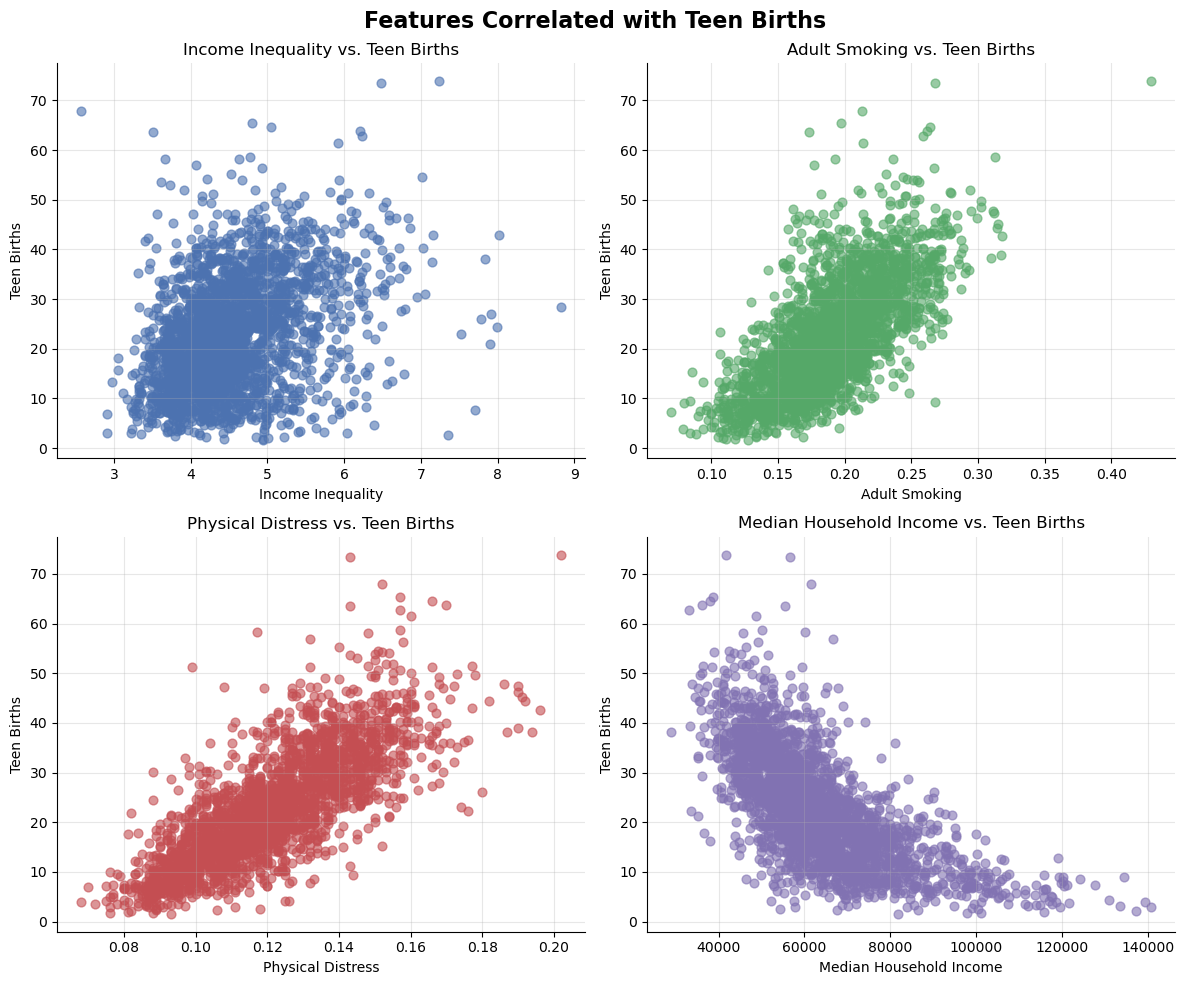

In [66]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Features Correlated with Teen Births', fontsize=16, fontweight='bold')

colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

y = df_final['Teen Births raw value']

# Plot 1: Income Inequality
axes[0,0].scatter(df_final['Income Inequality raw value'], y,
                  color=colors[0], alpha=0.6, s=40)
axes[0,0].set_title('Income Inequality vs. Teen Births')
axes[0,0].set_xlabel('Income Inequality')
axes[0,0].set_ylabel('Teen Births')

# Plot 2: Adult Smoking
axes[0,1].scatter(df_final['Adult Smoking raw value'], y,
                  color=colors[1], alpha=0.6, s=40)
axes[0,1].set_title('Adult Smoking vs. Teen Births')
axes[0,1].set_xlabel('Adult Smoking')
axes[0,1].set_ylabel('Teen Births')

# Plot 3: Physical Distress
axes[1,0].scatter(df_final['Frequent Physical Distress raw value'], y,
                  color=colors[2], alpha=0.6, s=40)
axes[1,0].set_title('Physical Distress vs. Teen Births')
axes[1,0].set_xlabel('Physical Distress')
axes[1,0].set_ylabel('Teen Births')

# Plot 4: Median Household Income
axes[1,1].scatter(df_final['Median Household Income raw value'], y,
                  color=colors[3], alpha=0.6, s=40)
axes[1,1].set_title('Median Household Income vs. Teen Births')
axes[1,1].set_xlabel('Median Household Income')
axes[1,1].set_ylabel('Teen Births')

for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

It seems that 'Frequent Physical Distress' has the strongest correlation with 'Teen Births'.

To explore this further, we will create lists including some features relevant to inequality, unhealthy habits (ex. smoking, drinking), physical health, and financial health. Finding the average of these indicators, we can consider which category is most closely correlated with teen births.

In [67]:
inequality = ['Income Inequality raw value','School Segregation raw value',
       'Gender Pay Gap raw value']
unhealthy_habits = ['Adult Smoking raw value','Excessive Drinking raw value',
       'Alcohol-Impaired Driving Deaths raw value',
       'Sexually Transmitted Infections raw value']
physical_health = ['Poor Physical Health Days raw value', 'Adult Obesity raw value','Frequent Physical Distress raw value','Diabetes Prevalence raw value',]
financial_health = ['Median Household Income raw value','Unemployment raw value', 'Children in Poverty raw value','Food Insecurity raw value']

df_teen_births = df_final[inequality + unhealthy_habits + physical_health + financial_health]
# standardizing data
df_teen_births = df_teen_births.apply(lambda col: (col - col.mean()) / col.std())

# most of these features have negative connotations, but median household income is positive, so this need to be converted to negative
df_teen_births['Median Household Income raw value'] = df_teen_births['Median Household Income raw value'] * -1
df_teen_births = df_teen_births.rename(columns={'Median Household Income raw value' : 'Low Household Income'})
financial_health[0]='Low Household Income'
df_teen_births.head()

,Income Inequality raw value,School Segregation raw value,Gender Pay Gap raw value,Adult Smoking raw value,Excessive Drinking raw value,Alcohol-Impaired Driving Deaths raw value,Sexually Transmitted Infections raw value,Poor Physical Health Days raw value,Adult Obesity raw value,Frequent Physical Distress raw value,Diabetes Prevalence raw value,Low Household Income,Unemployment raw value,Children in Poverty raw value,Food Insecurity raw value
3,0.141968,-0.453433,-0.385335,-0.543101,-0.645501,0.175727,0.754843,0.009145,0.366900,-0.168539,0.085624,-0.418719,-1.192243,-0.418683,0.539527
4,-0.073243,0.070629,-0.662237,-1.031449,-0.194858,0.749281,-0.305050,-0.283708,-0.020460,-0.515015,-0.351743,-0.519584,-1.121470,-0.367750,0.094295
5,1.444002,-0.621660,-0.018612,1.538803,-1.771642,0.365809,1.375906,1.827164,1.392265,1.860822,2.466841,1.460967,0.387068,2.382659,1.875225
6,1.572165,0.055420,0.349105,0.767728,-0.817430,-0.938770,1.105826,1.058469,0.526401,0.969883,0.911761,0.608020,-0.981001,0.829188,1.014442
7,0.106296,0.254559,1.141378,0.150867,-0.756458,-1.124926,-0.301781,0.557986,0.093470,0.375924,-0.011569,0.203262,-1.231331,-0.405950,0.658256


In [68]:
# create a column for the average of each category

df_teen_births['Inequality Indicator'] = df_teen_births[inequality].mean(axis=1)
df_teen_births['Unhealthy Habits Indicator'] = df_teen_births[unhealthy_habits].mean(axis=1)
df_teen_births['Physical Health Indicator'] = df_teen_births[physical_health].mean(axis=1)
df_teen_births['Financial Health Indicator'] = df_teen_births[financial_health].mean(axis=1)


df_teen_births.head()

,Income Inequality raw value,School Segregation raw value,Gender Pay Gap raw value,Adult Smoking raw value,Excessive Drinking raw value,Alcohol-Impaired Driving Deaths raw value,Sexually Transmitted Infections raw value,Poor Physical Health Days raw value,Adult Obesity raw value,Frequent Physical Distress raw value,Diabetes Prevalence raw value,Low Household Income,Unemployment raw value,Children in Poverty raw value,Food Insecurity raw value,Inequality Indicator,Unhealthy Habits Indicator,Physical Health Indicator,Financial Health Indicator
3,0.141968,-0.453433,-0.385335,-0.543101,-0.645501,0.175727,0.754843,0.009145,0.366900,-0.168539,0.085624,-0.418719,-1.192243,-0.418683,0.539527,-0.232267,-0.064508,0.073283,-0.372530
4,-0.073243,0.070629,-0.662237,-1.031449,-0.194858,0.749281,-0.305050,-0.283708,-0.020460,-0.515015,-0.351743,-0.519584,-1.121470,-0.367750,0.094295,-0.221617,-0.195519,-0.292732,-0.478627
5,1.444002,-0.621660,-0.018612,1.538803,-1.771642,0.365809,1.375906,1.827164,1.392265,1.860822,2.466841,1.460967,0.387068,2.382659,1.875225,0.267910,0.377219,1.886773,1.526480
6,1.572165,0.055420,0.349105,0.767728,-0.817430,-0.938770,1.105826,1.058469,0.526401,0.969883,0.911761,0.608020,-0.981001,0.829188,1.014442,0.658897,0.029338,0.866629,0.367662
7,0.106296,0.254559,1.141378,0.150867,-0.756458,-1.124926,-0.301781,0.557986,0.093470,0.375924,-0.011569,0.203262,-1.231331,-0.405950,0.658256,0.500744,-0.508074,0.253953,-0.193941


Now we can analyze which category has a greater impact on teen births.

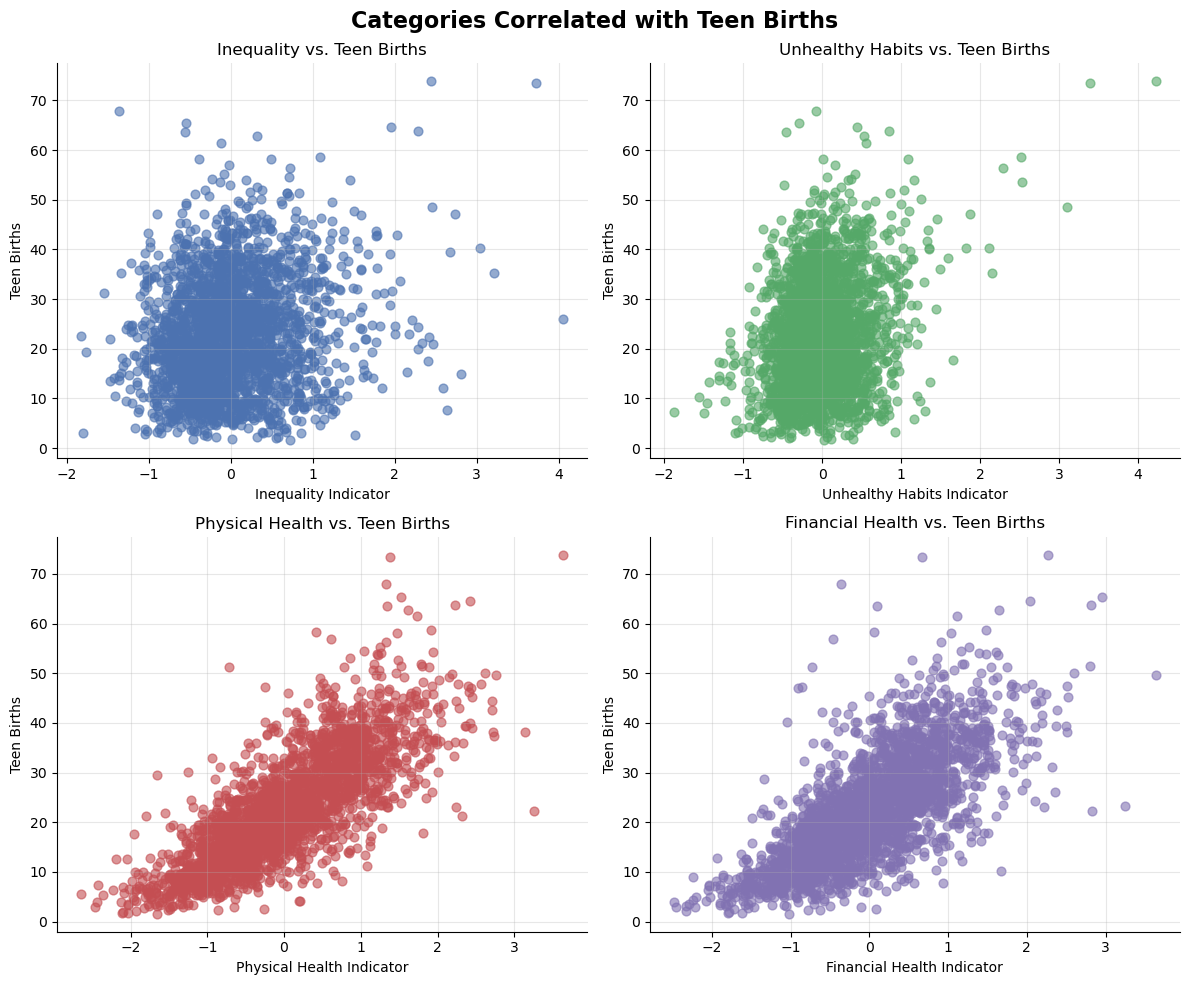

In [86]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Categories Correlated with Teen Births', fontsize=16, fontweight='bold')

colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

y = df_final['Teen Births raw value']

# Plot 1: Inequality
axes[0,0].scatter(df_teen_births['Inequality Indicator'], y,
                  color=colors[0], alpha=0.6, s=40)
axes[0,0].set_title('Inequality vs. Teen Births')
axes[0,0].set_xlabel('Inequality Indicator')
axes[0,0].set_ylabel('Teen Births')

# Plot 2: Unhealthy Habits
axes[0,1].scatter(df_teen_births['Unhealthy Habits Indicator'], y,
                  color=colors[1], alpha=0.6, s=40)
axes[0,1].set_title('Unhealthy Habits vs. Teen Births')
axes[0,1].set_xlabel('Unhealthy Habits Indicator')
axes[0,1].set_ylabel('Teen Births')

# Plot 3: Physical Health
axes[1,0].scatter(df_teen_births['Physical Health Indicator'], y,
                  color=colors[2], alpha=0.6, s=40)
axes[1,0].set_title('Physical Health vs. Teen Births')
axes[1,0].set_xlabel('Physical Health Indicator')
axes[1,0].set_ylabel('Teen Births')

# Plot 4: Financial Health
axes[1,1].scatter(df_teen_births['Financial Health Indicator'], y,
                  color=colors[3], alpha=0.6, s=40)
axes[1,1].set_title('Financial Health vs. Teen Births')
axes[1,1].set_xlabel('Financial Health Indicator')
axes[1,1].set_ylabel('Teen Births')

for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Asked ChatGPT, "How do you differentiate the colors between the different plots?"
# Source: https://matplotlib.org/3.3.0/api/_as_gen/matplotlib.pyplot.scatter.html?highlight=scatter&utm_source=chatgpt.com

Again, it seems that physical health has the strongest correlation with teen births.

Now, we will analyze the features correlated with **Children in Poverty**.

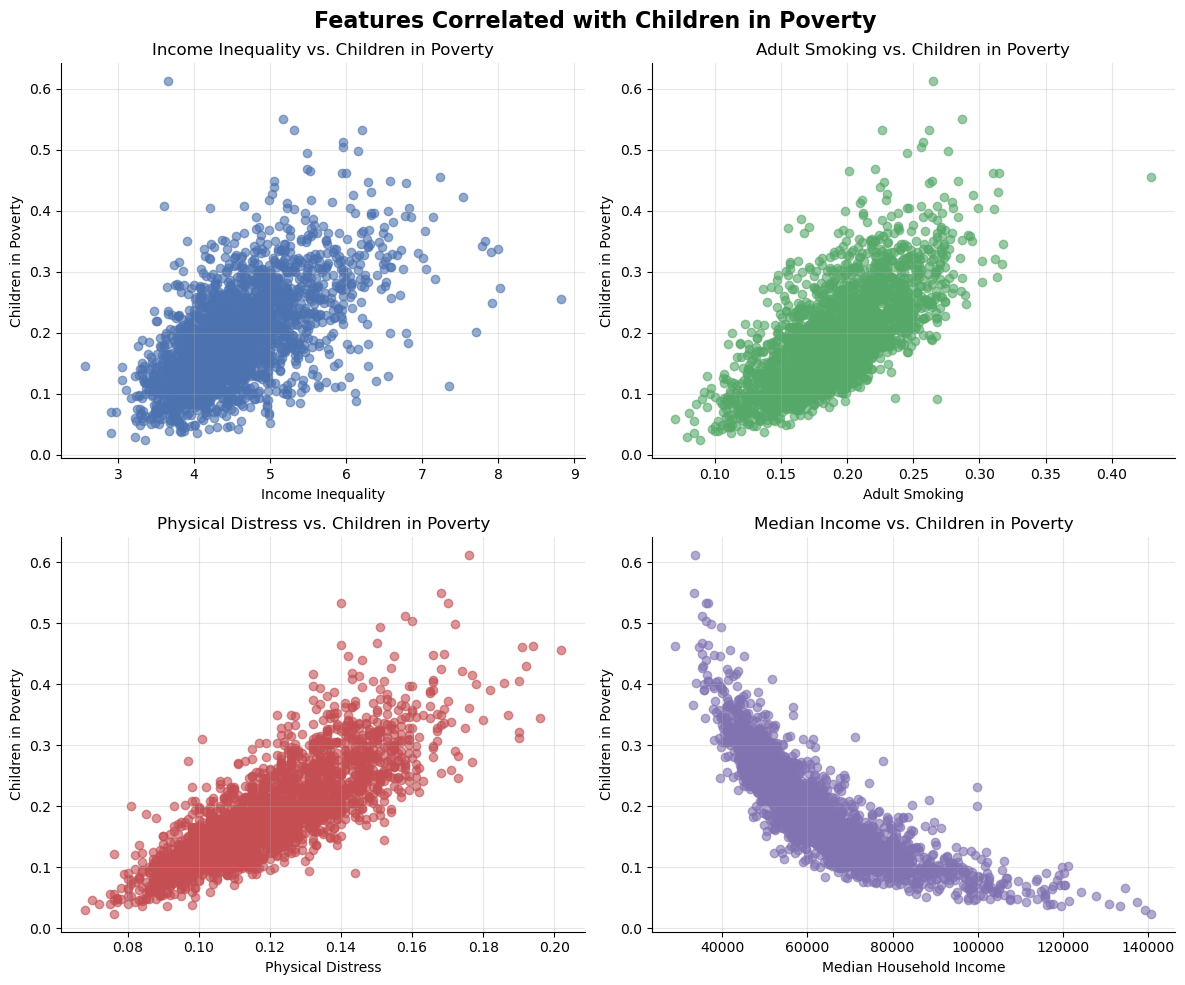

In [85]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Features Correlated with Children in Poverty', fontsize=16, fontweight='bold')

colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

# Plot 1
axes[0,0].scatter(df_final['Income Inequality raw value'],
                  df_final['Children in Poverty raw value'],
                  color=colors[0], alpha=0.6)
axes[0,0].set_title('Income Inequality vs. Children in Poverty')
axes[0,0].set_xlabel('Income Inequality')
axes[0,0].set_ylabel('Children in Poverty')

# Plot 2
axes[0,1].scatter(df_final['Adult Smoking raw value'],
                  df_final['Children in Poverty raw value'],
                  color=colors[1], alpha=0.6)
axes[0,1].set_title('Adult Smoking vs. Children in Poverty')
axes[0,1].set_xlabel('Adult Smoking')
axes[0,1].set_ylabel('Children in Poverty')

# Plot 3
axes[1,0].scatter(df_final['Frequent Physical Distress raw value'],
                  df_final['Children in Poverty raw value'],
                  color=colors[2], alpha=0.6)
axes[1,0].set_title('Physical Distress vs. Children in Poverty')
axes[1,0].set_xlabel('Physical Distress')
axes[1,0].set_ylabel('Children in Poverty')

# Plot 4
axes[1,1].scatter(df_final['Median Household Income raw value'],
                  df_final['Children in Poverty raw value'],
                  color=colors[3], alpha=0.6)
axes[1,1].set_title('Median Income vs. Children in Poverty')
axes[1,1].set_xlabel('Median Household Income')
axes[1,1].set_ylabel('Children in Poverty')

for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [71]:
inequality = ['Income Inequality raw value','School Segregation raw value',
       'Gender Pay Gap raw value']
unhealthy_habits = ['Adult Smoking raw value','Excessive Drinking raw value',
       'Alcohol-Impaired Driving Deaths raw value',
       'Sexually Transmitted Infections raw value']
physical_health = ['Poor Physical Health Days raw value', 'Adult Obesity raw value','Frequent Physical Distress raw value','Diabetes Prevalence raw value', 'Teen Births raw value']
financial_health = ['Median Household Income raw value','Unemployment raw value','Food Insecurity raw value']

df_children_poverty = df_final[inequality + unhealthy_habits + physical_health + financial_health]
# standardizing data
df_children_poverty = df_children_poverty.apply(lambda col: (col - col.mean()) / col.std())

# most of these features have negative connotations, but median household income is positive, so this need to be converted to negative
df_children_poverty['Median Household Income raw value'] = df_children_poverty['Median Household Income raw value'] * -1
df_children_poverty = df_children_poverty.rename(columns={'Median Household Income raw value' : 'Low Household Income'})
financial_health[0]='Low Household Income'
df_children_poverty.head()

,Income Inequality raw value,School Segregation raw value,Gender Pay Gap raw value,Adult Smoking raw value,Excessive Drinking raw value,Alcohol-Impaired Driving Deaths raw value,Sexually Transmitted Infections raw value,Poor Physical Health Days raw value,Adult Obesity raw value,Frequent Physical Distress raw value,Diabetes Prevalence raw value,Teen Births raw value,Low Household Income,Unemployment raw value,Food Insecurity raw value
3,0.141968,-0.453433,-0.385335,-0.543101,-0.645501,0.175727,0.754843,0.009145,0.366900,-0.168539,0.085624,-0.155316,-0.418719,-1.192243,0.539527
4,-0.073243,0.070629,-0.662237,-1.031449,-0.194858,0.749281,-0.305050,-0.283708,-0.020460,-0.515015,-0.351743,-0.218989,-0.519584,-1.121470,0.094295
5,1.444002,-0.621660,-0.018612,1.538803,-1.771642,0.365809,1.375906,1.827164,1.392265,1.860822,2.466841,1.260224,1.460967,0.387068,1.875225
6,1.572165,0.055420,0.349105,0.767728,-0.817430,-0.938770,1.105826,1.058469,0.526401,0.969883,0.911761,0.837124,0.608020,-0.981001,1.014442
7,0.106296,0.254559,1.141378,0.150867,-0.756458,-1.124926,-0.301781,0.557986,0.093470,0.375924,-0.011569,0.224424,0.203262,-1.231331,0.658256


In [72]:
# create a column for the average of each category

df_children_poverty['Inequality Indicator'] = df_children_poverty[inequality].mean(axis=1)
df_children_poverty['Unhealthy Habits Indicator'] = df_children_poverty[unhealthy_habits].mean(axis=1)
df_children_poverty['Physical Health Indicator'] = df_children_poverty[physical_health].mean(axis=1)
df_children_poverty['Financial Health Indicator'] = df_children_poverty[financial_health].mean(axis=1)


df_children_poverty.head()

,Income Inequality raw value,School Segregation raw value,Gender Pay Gap raw value,Adult Smoking raw value,Excessive Drinking raw value,Alcohol-Impaired Driving Deaths raw value,Sexually Transmitted Infections raw value,Poor Physical Health Days raw value,Adult Obesity raw value,Frequent Physical Distress raw value,Diabetes Prevalence raw value,Teen Births raw value,Low Household Income,Unemployment raw value,Food Insecurity raw value,Inequality Indicator,Unhealthy Habits Indicator,Physical Health Indicator,Financial Health Indicator
3,0.141968,-0.453433,-0.385335,-0.543101,-0.645501,0.175727,0.754843,0.009145,0.366900,-0.168539,0.085624,-0.155316,-0.418719,-1.192243,0.539527,-0.232267,-0.064508,0.027563,-0.357145
4,-0.073243,0.070629,-0.662237,-1.031449,-0.194858,0.749281,-0.305050,-0.283708,-0.020460,-0.515015,-0.351743,-0.218989,-0.519584,-1.121470,0.094295,-0.221617,-0.195519,-0.277983,-0.515587
5,1.444002,-0.621660,-0.018612,1.538803,-1.771642,0.365809,1.375906,1.827164,1.392265,1.860822,2.466841,1.260224,1.460967,0.387068,1.875225,0.267910,0.377219,1.761463,1.241087
6,1.572165,0.055420,0.349105,0.767728,-0.817430,-0.938770,1.105826,1.058469,0.526401,0.969883,0.911761,0.837124,0.608020,-0.981001,1.014442,0.658897,0.029338,0.860728,0.213820
7,0.106296,0.254559,1.141378,0.150867,-0.756458,-1.124926,-0.301781,0.557986,0.093470,0.375924,-0.011569,0.224424,0.203262,-1.231331,0.658256,0.500744,-0.508074,0.248047,-0.123271


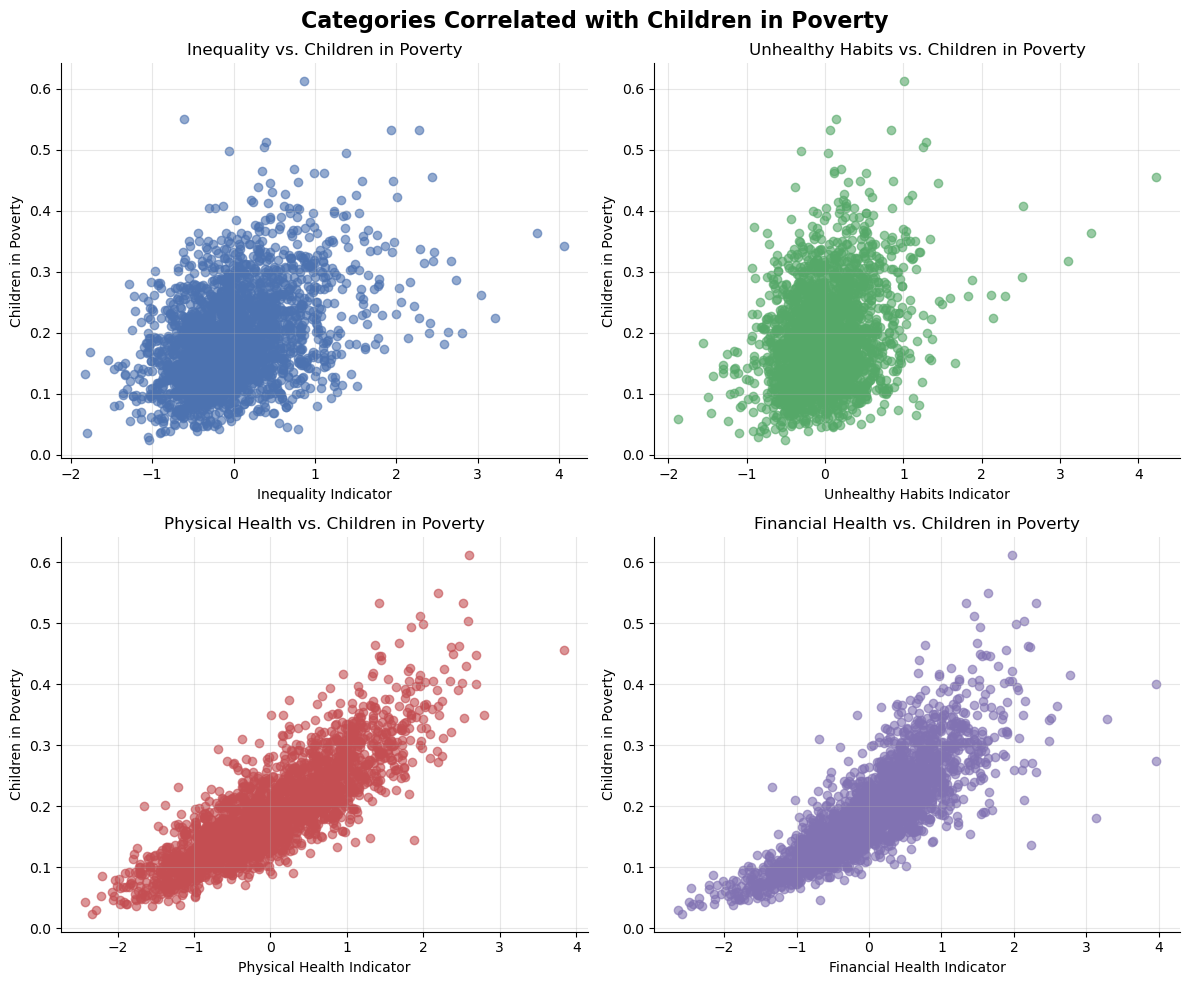

In [87]:
# Create figure and axes
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Categories Correlated with Children in Poverty', fontsize=16, fontweight='bold')

# Consistent color palette
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

y = df_final['Children in Poverty raw value']

# Plot 1: Inequality
axes[0,0].scatter(df_children_poverty['Inequality Indicator'], y,
                  color=colors[0], alpha=0.6)
axes[0,0].set_title('Inequality vs. Children in Poverty')
axes[0,0].set_xlabel('Inequality Indicator')
axes[0,0].set_ylabel('Children in Poverty')

# Plot 2: Unhealthy Habits
axes[0,1].scatter(df_children_poverty['Unhealthy Habits Indicator'], y,
                  color=colors[1], alpha=0.6)
axes[0,1].set_title('Unhealthy Habits vs. Children in Poverty')
axes[0,1].set_xlabel('Unhealthy Habits Indicator')
axes[0,1].set_ylabel('Children in Poverty')

# Plot 3: Physical Health
axes[1,0].scatter(df_children_poverty['Physical Health Indicator'], y,
                  color=colors[2], alpha=0.6)
axes[1,0].set_title('Physical Health vs. Children in Poverty')
axes[1,0].set_xlabel('Physical Health Indicator')
axes[1,0].set_ylabel('Children in Poverty')

# Plot 4: Financial Health
axes[1,1].scatter(df_children_poverty['Financial Health Indicator'], y,
                  color=colors[3], alpha=0.6)
axes[1,1].set_title('Financial Health vs. Children in Poverty')
axes[1,1].set_xlabel('Financial Health Indicator')
axes[1,1].set_ylabel('Children in Poverty')

for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

It seems that Children in Poverty has strongest correlation with physical health, and this correlation is even stronger than physical health and Teen Births.

## 3. Asking the Hard Questions

By now we should know all of the ins and outs about this dataset (right?). Let's dive a little deeper into it and see if we can find anything interesting.

### Problem 4

As you worked through the initial data processing and understanding phase, did anything catch your interest? Let's formulate some questions and hypotheses that you could explore in depth.

**Write-up!** Formulate and describe a question you have/want to investigate. Then, formulate and describe a hypothesis that can (possibly) answer it. What inspired your idea (provide specifics from [the last section](#2.-Getting-Familiar-with-the-Data), if any)? How can you use the data to support or reject your hypothesis?

> **Hint**: Your question/hypothesis might be something that you are personally interested in or something that you think might lead to a product or service for users/customers. You might want to think about something that could help others in making decisions, etc.

*Grading Note: Your work will be graded for _creativity_. Be creative in the questions you ask/hypothesis you pose.* 

**Answer here:** (feel free to make multiple cells!)

Question: What features, besides financial indicators, best predict childhood poverty?

Hypothesis: Physical indicators have the strongest correlation with childhood poverty, so some combination of these indicators will be the best predictor.

We can create machine learning models that predict childhood poverty based on different features, and use evaluation methods to determine which one is most accurate.

In the last section, we analyzed the features that are correlated with childhood poverty, and discovered that physical indicators are strongly correlated.

If we can identify the features that are most closely tied to childhood poverty, we can understand the impact of it, and think about how to limit it.

### Problem 5

**Do this!** Let's explore your hypothesis. Find evidence from the data that supports or refutes your hypothesis and present it — recall that as a data scientist, one of your goals is to discover and communicate your results to your audience, _me_. The more thorough your analysis, the better!

> **Hint**: Even though we focus on EDA here, you may include some predictive modeling here as well. 

Here's yet another _free_ cell; use as many as you need.

In [74]:
# woah! these things are falling from the sky or something

We need a dataframe with Children in Poverty as the target, and all of the features that we will be considering.

In [75]:
child_poverty = df_final[['Premature Death raw value','Poor Physical Health Days raw value','Poor Mental Health Days raw value', 'Low Birthweight raw value',
       'Adult Smoking raw value', 'Adult Obesity raw value',
       'Food Environment Index raw value', 'Physical Inactivity raw value',
       'Access to Exercise Opportunities raw value',
       'Excessive Drinking raw value',
       'Alcohol-Impaired Driving Deaths raw value',
       'Sexually Transmitted Infections raw value', 'Teen Births raw value',
       'Uninsured raw value','Preventable Hospital Stays raw value','Flu Vaccinations raw value','Air Pollution - Particulate Matter raw value',
       'Drinking Water Violations raw value','Driving Alone to Work raw value',
       'Long Commute - Driving Alone raw value', 'Frequent Physical Distress raw value',
       'Frequent Mental Distress raw value', 'Diabetes Prevalence raw value',
       'Food Insecurity raw value','Insufficient Sleep raw value','% Below 18 Years of Age raw value']].copy()
child_poverty['Children in Poverty raw value'] = df_final['Children in Poverty raw value']

# remove 'raw value' to make things simpler
child_poverty = child_poverty.rename(columns=lambda col: col.replace('raw value', '').strip()
               if col.endswith('raw value') else col)
child_poverty

,Premature Death,Poor Physical Health Days,Poor Mental Health Days,Low Birthweight,Adult Smoking,Adult Obesity,Food Environment Index,Physical Inactivity,Access to Exercise Opportunities,Excessive Drinking,...,Drinking Water Violations,Driving Alone to Work,Long Commute - Driving Alone,Frequent Physical Distress,Frequent Mental Distress,Diabetes Prevalence,Food Insecurity,Insufficient Sleep,% Below 18 Years of Age,Children in Poverty
3,9407.948438,3.910265,5.703204,0.098713,0.169,0.389,6.7,0.291,0.544920,0.152378,...,0,0.854278,0.429,0.117,0.180,0.107,0.133,0.375,0.232283,0.157
4,8981.575353,3.730943,5.373666,0.081243,0.150,0.372,7.5,0.276,0.631293,0.164226,...,1,0.813470,0.379,0.110,0.173,0.098,0.118,0.351,0.208039,0.161
5,13138.848362,5.023488,6.014294,0.122725,0.250,0.434,6.0,0.402,0.548547,0.122772,...,0,0.820525,0.367,0.158,0.205,0.156,0.178,0.439,0.203635,0.377
6,12675.434581,4.552795,5.824583,0.098286,0.220,0.396,7.6,0.360,0.433903,0.147858,...,0,0.879836,0.538,0.140,0.194,0.124,0.149,0.400,0.197455,0.255
7,11541.495069,4.246335,5.664851,0.076043,0.196,0.377,7.7,0.304,0.413552,0.149461,...,0,0.848947,0.606,0.128,0.188,0.105,0.137,0.373,0.227047,0.158
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3191,9732.214769,3.637753,5.213634,0.100881,0.178,0.343,7.9,0.257,0.926216,0.193452,...,1,0.772692,0.192,0.107,0.161,0.088,0.114,0.304,0.247382,0.149
3192,4267.876402,2.544521,4.105952,0.077519,0.111,0.217,8.7,0.161,0.992285,0.230960,...,1,0.599368,0.125,0.080,0.127,0.066,0.084,0.265,0.171297,0.053
3193,11027.136279,3.405617,4.957677,0.096607,0.168,0.333,8.5,0.228,0.636626,0.166655,...,0,0.796895,0.181,0.106,0.157,0.083,0.103,0.353,0.268395,0.132
3194,8065.688093,3.378598,4.623766,0.064457,0.164,0.336,8.6,0.229,0.763565,0.159019,...,0,0.782915,0.091,0.104,0.153,0.084,0.093,0.312,0.207799,0.143


Now, we will create a machine learning model that considers all of these features to get an upper bound for the accuracy of a model.

In [76]:
# training phase
from sklearn.model_selection import train_test_split
X1 = child_poverty.iloc[:, :-1].to_numpy()
y = child_poverty.iloc[:,-1].to_numpy()

X1_train, X1_test, y_train, y_test = train_test_split(X1, y, test_size=0.2, random_state=10)

from sklearn.linear_model import LinearRegression
model1 = LinearRegression()
model1.fit(X1_train, y_train)

# testing phase
y1_pred = model1.predict(X1_test)

# evaluation phase
from sklearn.metrics import r2_score
r2_1 = r2_score(y_test, y1_pred)
r2_1

0.8356608100393719

Now we will consider only the physical health indicators.

In [77]:
physical = ['Premature Death','Poor Physical Health Days', 'Low Birthweight','Adult Obesity','Physical Inactivity',
            'Access to Exercise Opportunities','Preventable Hospital Stays','Flu Vaccinations',
            'Frequent Physical Distress','Diabetes Prevalence','Food Insecurity']
# training
X2 = child_poverty.loc[:,physical].to_numpy()

X2_train, X2_test, y_train, y_test = train_test_split(X2, y, test_size=0.2, random_state=10)

model2 = LinearRegression()
model2.fit(X2_train, y_train)

# testing
y2_pred = model2.predict(X2_test)

# evaluation
r2_2 = r2_score(y_test, y2_pred)
r2_2

0.8034882285153409

We can compare this to a model built off of all features that don't include physical health.

In [78]:
# train
X3 = child_poverty.loc[:,[col for col in child_poverty.columns if col not in physical and col != 'Children in Poverty']]

X3_train, X3_test, y_train, y_test = train_test_split(X3, y, test_size=0.2, random_state=10)

model3 = LinearRegression()
model3.fit(X3_train, y_train)

# test
y3_pred = model3.predict(X3_test)

# evaluate
r2_3 = r2_score(y_test, y3_pred)
r2_3

0.7722085630829176

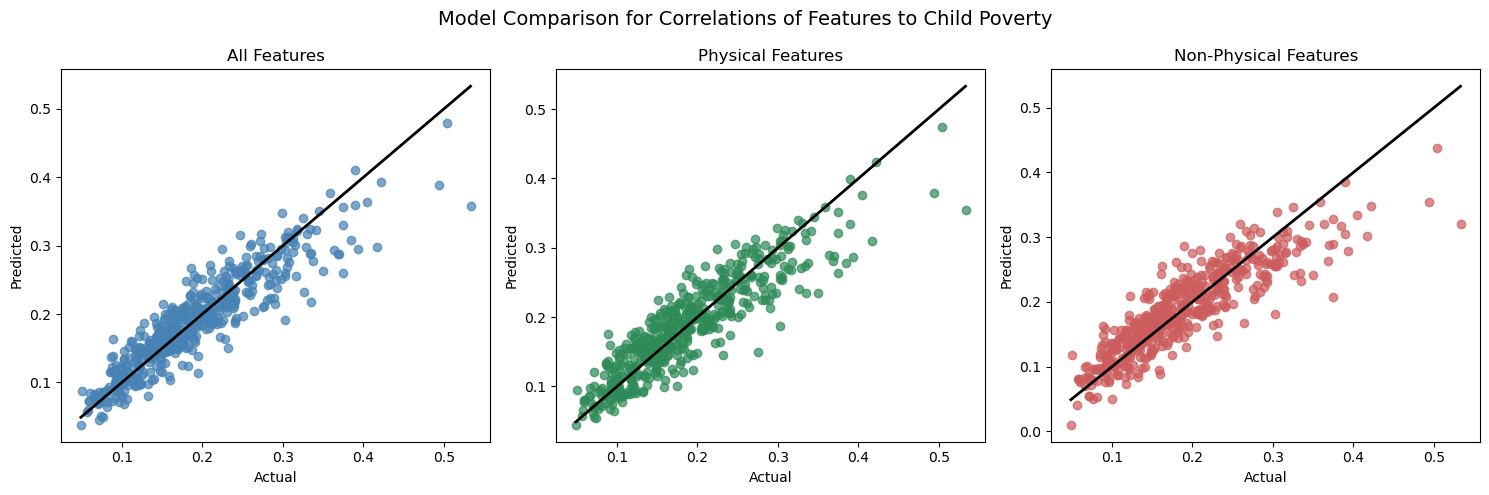

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = [
    (y1_pred, "All Features"),
    (y2_pred, "Physical Features"),
    (y3_pred, "Non-Physical Features")
]

colors = ["steelblue", "seagreen", "indianred"]  # distinct but clean

for ax, (pred, title), color in zip(axes, models, colors):
    ax.scatter(y_test, pred, alpha=0.7, color=color)
    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        linewidth=2,
        color="black"  # keep reference line consistent
    )
    ax.set_title(title)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")

plt.suptitle("Model Comparison for Correlations of Features to Child Poverty", fontsize=14)
plt.tight_layout()
plt.show()

Evidently, considering all the features together produces better results than splitting the features in half and training them separately. However, considering only physical features produced an R^2 value of 0.750, while considering all other features produced an R^2 value of 0.678. These are both worse than the R^2 value 0.794 produced by looking at all our chosen features, but we can see that physical features are better predictors of child poverty.

We considered 11 physical features and 15 non-physical features, indicating that the accuracy was not higher because more features were considered.

Now we can split this up further, into physical activity, healthy eating, and sickness.

In [79]:
physical_activity = ['Adult Obesity','Physical Inactivity','Access to Exercise Opportunities']
healthy_eating = ['Adult Obesity','Diabetes Prevalence','Food Insecurity']
# note that we are considering 'Adult Obesity' in both physical activity and healthy eating, because it is relevant for both
sickness = ['Premature Death','Poor Physical Health Days','Preventable Hospital Stays','Frequent Physical Distress']

Physical activity:

In [80]:
# train
X4 = child_poverty.loc[:,physical_activity]

X4_train, X4_test, y_train, y_test = train_test_split(X4, y, test_size=0.2, random_state=10)

model4 = LinearRegression()
model4.fit(X4_train, y_train)

# test
y4_pred = model4.predict(X4_test)

# evaluate
r2_4 = r2_score(y_test, y4_pred)
r2_4

0.5463255009899308

Healthy eating:

In [81]:
# train
X5 = child_poverty.loc[:,healthy_eating]

X5_train, X5_test, y_train, y_test = train_test_split(X5, y, test_size=0.2, random_state=10)

model5 = LinearRegression()
model5.fit(X5_train, y_train)

# test
y5_pred = model5.predict(X5_test)

# evaluate
r2_5 = r2_score(y_test, y5_pred)
r2_5

0.7542935522685734

Sickness:

In [82]:
# train
X6 = child_poverty.loc[:,sickness]

X6_train, X6_test, y_train, y_test = train_test_split(X6, y, test_size=0.2, random_state=10)

model6 = LinearRegression()
model6.fit(X6_train, y_train)

# test
y6_pred = model6.predict(X6_test)

# evaluate
r2_6 = r2_score(y_test, y6_pred)
r2_6

0.7304198668652142

We have seen that out of the three subsets of physical health, healthy eating is the most predictive of child poverty, with an R^2 value of 0.643 compared to 0.182 for physical activity and 0.623 for sickness. The sickness subset had one more feature than the other two, but healthy eating still performed better. Thus, we can see that healthy eating is very closely tied to child poverty.

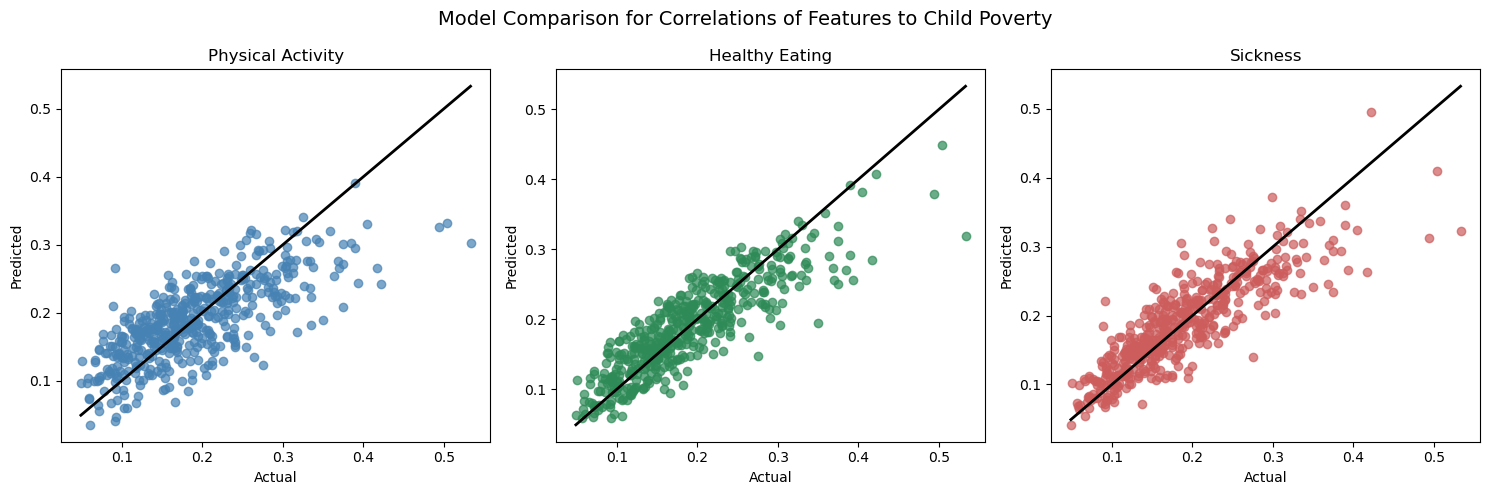

In [88]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models = [
    (y4_pred, "Physical Activity"),
    (y5_pred, "Healthy Eating"),
    (y6_pred, "Sickness")
]

colors = ["steelblue", "seagreen", "indianred"]  # distinct but clean

for ax, (pred, title), color in zip(axes, models, colors):
    ax.scatter(y_test, pred, alpha=0.7, color=color)
    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        linewidth=2,
        color="black"  # keep reference line consistent
    )
    ax.set_title(title)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")

plt.suptitle("Model Comparison for Correlations of Features to Child Poverty", fontsize=14)
plt.tight_layout()
plt.show()

### Problem 6

**Write up!** Did you find anything interesting in [Problem 5](#Problem-5)? If you did, tell me about it. If you don't think you found anything interesting, keep looking. 

> **Hint**: Provide links to key figures in your discussion. See [this StackOverflow question](https://stackoverflow.com/questions/28080066/how-to-reference-a-ipython-notebook-cell-in-markdown) for details.

**Answer here:** (feel free to make multiple cells!)

In Problem 5, we discovered that healthy eating has a relatively high correlation with child poverty. A machine learning model will be more accurate when more features are included, so we wouldn't want to only consider healthy eating when predicting child poverty, but it is interesting to note the high correlation, higher than non-physical components or other physical components such as physical activity and sickness. It is important to note that unhealthy eating doesn't necessarily cause child poverty; it could be that child poverty causes unhealthy eating. Either way, it is interesting that there is such a strong correlation, and this observation could be used to determine how to best improve conditions for children in poverty; for example, healthier meals in school cafeterias.

It was also interesting that for all correlations of the features to "Child Poverty", the dots in the scatter plot were clustered tightly together near the line when poverty is low, but as the x-value increases, the dots scatter away from the line. This could be because as poverty increases, there is greater variation of other variables that come into effect like access to healthcare, food deserts, education, and even policy differences. Whereas when poverty values are low to medium, the measures that countries could take are similar and thus are closer to the regression line.

### Problem 7
One last step that we shouldn't skip is reviewing both our data analysis approach and also the data acquisition method. 

**Write up!** Are there any **shortcommings** related to the way you used or processed this data? How about the methods/arguments you used to form your conclusions?

**Answer here:** (feel free to make multiple cells!)

First of all, instead of directly reflecting the complex and multifactorial nature of child poverty, relying on single predictors like physical activity and healthy eating oversimplifies the real life problem. In reality, child poverty is influenced by a wide range of interacting variables, including income, education, housing stability, and access to healthcare. This limits explanatory power and creates potential bias.

For example, the visualizations revealed a pattern of increasing spread at higher values, indicating heteroscedasticity. Thus, conclusions drawn from these models may not generalize well to high-poverty regions, where variability is greater and underlying conditions are more diverse.

Last but not least, although R squared measures the proportion of variance explained, it does not capture issues such as bias, distribution of errors, or performance across different ranges of the data. As a result, relying solely on R² may oversimplify the evaluation and lead to overconfident interpretations.

Overall, while the analysis identifies general trends, the methods and data processing choices limit the strength of the conclusions.

**Write up!** Let's critcially review our work in the light of **ethical data science**. 
* Name at least two ethical issues related to the way you used or processed this data and/or the methods/arguments you used to form your conclusions.
* Who are the stakeholders?
* How could someone other than yourself be impacted by any ethical issues arising from your analysis/work/product?
* Propose a way to resolve the issue(s).

**Answer here:** (feel free to make multiple cells!)

One possible ethical issue is that we did not consider any feautures related to race or gender. While it would also not be a good idea to include them as any other feature, simply removing the features does not remove the latent bias implicated by them, which may have kept racist and misogynistic biases in our data. Also, we are not accounting for inequality within counties. While a county may seem to have low child poverty, it is possible that there is actually inequality within the county, and the data is simply reporting the average. This could lead to the neglect of those in lower percentiles in these counties.

Stakeholds include people who live in these counties, policymakers, and people aiming to improve child poverty.

If someone living in a county with a low reported rate of child poverty is actually struggling with it, our work may leave them without help, since we are only using general county data.

While the data does include an 'Income Inequality' feature, we could resolve the issue by also collecting data on inequality of other features such as child poverty (which is correlated with income but is not necessarily the same thing). We could include information not only about the average of the county, but about the entire distribution. This would help us be more informed about everyone in the county, not just the average that may be skewed. This would be helpful not only for the child poverty feature, but for all other features we used.

Let's conclude with thinking about **imporvements for the future**! 

**Write up!** There are often times where the data you need doesn't exist (yet) and you need to go collect it. Based on your analysis of the data set, which features were informative and which weren't? What information that was missing from this dataset do you think would be helpful to have for next time?

**Answer here:** (feel free to make multiple cells!)

For our analysis, we didn't much consider financial features other than child poverty. Features about physical health were especially helpful, as well as other features such as inequality and unhealthy habits.

It would have been more helpful to have more information about inequality, not just about financial inequality, but about the entire distribution among the county for each of the features.

### Problem 8

**Write up!** Did you use any generative AI tools (ChatGPT, Copilot, etc.) for this project?
* Which generative AI tools did you use?
* How did you them? 
* How did you ensure that your project reflects your own understanding?
* What challenges or adjustments did you encounter when using generative AI (refining prompts, verifying accuracy, revising outputs, etc.)?

**Answer here:** (feel free to make multiple cells!)

After creating the scatterplots and graphs, we used ChatGPT to enhance their visual aesthetics. The prompts used were "How do you differentiate the colors between the different plots?" and "Are there ways to visually enhance these graphs?"

When using AI, we made sure that we fully understood the code we were using before implementing it.

### Problem 9

**Write up!** What was your division of work plan?
* Which partner did which sections?
* Was the work split evenly?

**Answer here:** (feel free to make multiple cells!)

Erica: Problem 1, Problem 2 dataframe 1-3, Problem 3 Heatmap and correlations to children in poverty + improvement in visual graphs, Problem 5 visual comparison (graph), Problem 6 writeup, and Problem 7 part 1.

Ilana: Problem 2 dataframes 4-6, Problem 3 correlations to teen births, Problem 5 machine learning models, Problem 7 part 2-3.

We worked on Problems 8 and 9 together.

And that's it! Remember to review your work and make sure it is well presented and organized. Not everyting you coded up needs to remain in your submission. **[Does [this cell] spark joy?](https://i.kinja-img.com/gawker-media/image/upload/s--iW_3HGbT--/c_scale,dpr_2.0,f_auto,fl_progressive,q_80,w_800/oruf4oavtj5vpmvaquew.jpg)** You are always trying to communicate your findings to somebody, _maybe even yourself_. 

> **Final Grading Note/Reminder**: Your work will be graded for _creativity_, _aesthetics_, _readability_, _style_, and _cleanlines_. So, carefully document your code and use descriptive/intuitive variable names. For write-ups use consice and clear language like in a written project report. Be creative in the questions you ask/hypothesis you pose as well as in the plots you use and select visulatizations and colors that make for a plesant and intuitive viewing expereince. The goal of a good visualization is that the viewer will quickly understand your figures. 

### Submission instructions
* Check to make sure that your code runs without error on a fresh kernel. Within jupyter, **Kernel -> Restart & Run All**. 
* **Save your notebook!**
* Submit this Python notebook, including your answers in the code cells as homework submission. Be sure to add your partner to the submission as well.
* After submitting, navigate to the **code tab** to view your submission. Verify that all your write-ups, markdown cells, and visualizations appear correctly on Gradescope. This is the **exact** view the graders will see when grading your work, so make sure that everything looks as expected.

In [ ]:
grader.check("hw6")

<!-- END QUESTION -->

